In [1]:
import multixrank
import os
import pandas as pd
import random
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

In [2]:
CURRENT_DIR = os.getcwd()
CANCER_HALLMARKS_FOLDER = os.path.join(CURRENT_DIR, "../../../../Data/ValidationData/CancerHallmarks")
REACTOME_COMEMBERSHIP_CLIQUE = pd.read_csv(os.path.join(CURRENT_DIR, "../../../../Results/PathwayComembership/06_ScalingReactome/Reactome_ComembershipClique.csv"), sep=",", header=0)
REACTOME_WEIGHTED_COMEMBERSHIP_CLIQUE = pd.read_csv(os.path.join(CURRENT_DIR, "../../../../Results/PathwayComembership/06_ScalingReactome/Reactome96WeightedComembershipClique.csv"), sep=",", header=0)
REACTOME_WEIGHTED_COMEMBERSHIP_CLIQUE_NO_NSP = pd.read_csv(os.path.join(CURRENT_DIR, "../../../../Results/PathwayComembership/06_ScalingReactome/Reactome96WeightedComembershipClique_NO_NSP.csv"), sep=",", header=0)

In [3]:
ReactomeCliqueNtw = nx.from_pandas_edgelist(REACTOME_COMEMBERSHIP_CLIQUE, source = "id1", target = "id2")

In [9]:
ReactomeWeightedCliqueNtw = nx.from_pandas_edgelist(REACTOME_WEIGHTED_COMEMBERSHIP_CLIQUE, source="prot1", target="prot2", edge_attr="comembershipScore")

In [3]:
ReactomeWeightedCliqueNoNSPNtw = nx.from_pandas_edgelist(REACTOME_WEIGHTED_COMEMBERSHIP_CLIQUE_NO_NSP, source="prot1", target="prot2", edge_attr="comembershipScore")

### 1 - Get back gene sets files

In [4]:
TISSUE_INVASION_METASTASIS = pd.read_csv(os.path.join(CANCER_HALLMARKS_FOLDER, "TissueInvasionAndMetastasis-UniProt.tsv"), sep="\t", header=0)
REPROGRAMMING_ENERGY_METABOLISM = pd.read_csv(os.path.join(CANCER_HALLMARKS_FOLDER, "ReprogrammingEnergyMetabolism-UniProt.tsv"), sep="\t", header=0)
REPLICATIVE_IMMORTALITY = pd.read_csv(os.path.join(CANCER_HALLMARKS_FOLDER, "ReplicativeImmortality-UniProt.tsv"), sep="\t", header=0)
GENOME_INSTABILITY = pd.read_csv(os.path.join(CANCER_HALLMARKS_FOLDER, "GenomeInstability-UniProt.tsv"), sep="\t", header=0)
RESISTING_CELL_DEATH = pd.read_csv(os.path.join(CANCER_HALLMARKS_FOLDER, "ResistingCellDeath-UniProt.tsv"), sep="\t", header=0)
EVADING_GROWTH_SUPPRESSORS = pd.read_csv(os.path.join(CANCER_HALLMARKS_FOLDER, "EvadingGrowthSuppressors-UniProt.tsv"), sep="\t", header=0)
EVADING_IMMUNE_DESTRUCTION = pd.read_csv(os.path.join(CANCER_HALLMARKS_FOLDER, "EvadingImmuneDestruction-UniProt.tsv"), sep="\t", header=0)
SUSTAINED_ANGIOGENESIS = pd.read_csv(os.path.join(CANCER_HALLMARKS_FOLDER, "SustainedAngiogenesis-UniProt.tsv"), sep="\t", header=0)
SUSTAINING_PROLIFERATIVE_SIGNALING = pd.read_csv(os.path.join(CANCER_HALLMARKS_FOLDER, "SustainingProliferativeSignaling-UniProt.tsv"), sep="\t", header=0)
TUMOR_PROMOTING_INFLAMMATION = pd.read_csv(os.path.join(CANCER_HALLMARKS_FOLDER, "TumorPromotingInflammation-UniProt.tsv"), sep="\t", header=0)

In [5]:
TISSUE_INVASION_METASTASIS_LIST_PROT = TISSUE_INVASION_METASTASIS["Entry"].to_list()
REPROGRAMMING_ENERGY_METABOLISM_LIST_PROT = REPROGRAMMING_ENERGY_METABOLISM["Entry"].to_list()
REPLICATIVE_IMMORTALITY_LIST_PROT = REPLICATIVE_IMMORTALITY["Entry"].to_list()
GENOME_INSTABILITY_LIST_PROT = GENOME_INSTABILITY["Entry"].to_list()
RESISTING_CELL_DEATH_LIST_PROT = RESISTING_CELL_DEATH["Entry"].to_list()
EVADING_GROWTH_SUPPRESSORS_LIST_PROT = EVADING_GROWTH_SUPPRESSORS["Entry"].to_list()
EVADING_IMMUNE_DESTRUCTION_LIST_PROT = EVADING_IMMUNE_DESTRUCTION["Entry"].to_list()
SUSTAINED_ANGIOGENESIS_LIST_PROT = SUSTAINED_ANGIOGENESIS["Entry"].to_list()
SUSTAINING_PROLIFERATIVE_SIGNALING_LIST_PROT = SUSTAINING_PROLIFERATIVE_SIGNALING["Entry"].to_list()
TUMOR_PROMOTING_INFLAMMATION_LIST_PROT = TUMOR_PROMOTING_INFLAMMATION["Entry"].to_list()

In [ ]:
list_hallmarks_files = [
    TISSUE_INVASION_METASTASIS,
    REPROGRAMMING_ENERGY_METABOLISM,
    REPLICATIVE_IMMORTALITY,
    GENOME_INSTABILITY,
    RESISTING_CELL_DEATH,
    EVADING_GROWTH_SUPPRESSORS,
    EVADING_IMMUNE_DESTRUCTION,
    SUSTAINED_ANGIOGENESIS,
    SUSTAINING_PROLIFERATIVE_SIGNALING,
    TUMOR_PROMOTING_INFLAMMATION
    ]

HALLMARKS = [
    TISSUE_INVASION_METASTASIS_LIST_PROT,
    REPROGRAMMING_ENERGY_METABOLISM_LIST_PROT,
    REPLICATIVE_IMMORTALITY_LIST_PROT,
    GENOME_INSTABILITY_LIST_PROT,
    RESISTING_CELL_DEATH_LIST_PROT,
    EVADING_GROWTH_SUPPRESSORS_LIST_PROT,
    EVADING_IMMUNE_DESTRUCTION_LIST_PROT,
    SUSTAINED_ANGIOGENESIS_LIST_PROT,
    SUSTAINING_PROLIFERATIVE_SIGNALING_LIST_PROT,
    TUMOR_PROMOTING_INFLAMMATION_LIST_PROT
]

dico_hallmarks_ids = {
    "01": "TISSUE_INVASION_METASTASIS",
    "02": "REPROGRAMMING_ENERGY_METABOLISM",
    "03": "REPLICATIVE_IMMORTALITY",
    "04": "GENOME_INSTABILITY",
    "05": "RESISTING_CELL_DEATH",
    "06": "EVADING_GROWTH_SUPPRESSORS",
    "07": "EVADING_IMMUNE_DESTRUCTION",
    "08": "SUSTAINED_ANGIOGENESIS",
    "09": "SUSTAINING_PROLIFERATIVE_SIGNALING",
    "10": "TUMOR_PROMOTING_INFLAMMATION"
}

In [7]:
# HALLMARKS_IN_REACTOME = dict()

# counter = 1
# for hallmark_prot_list in HALLMARKS:
#     hallmark_name = dico_hallmarks_ids[f"{counter:02d}"]
#     prot_in_reactome = list()
#     for prot in hallmark_prot_list:
#         if prot in ReactomeWeightedCliqueNtw.nodes():
#             prot_in_reactome.append(prot)
#     HALLMARKS_IN_REACTOME[hallmark_name] = prot_in_reactome
#     counter += 1

# print(HALLMARKS_IN_REACTOME)
# print(HALLMARKS_IN_REACTOME.keys())

HALLMARKS_IN_REACTOME = dict()

counter = 1
for hallmark_prot_list in HALLMARKS:
    hallmark_name = dico_hallmarks_ids[f"{counter:02d}"]
    prot_in_reactome = list()
    for prot in hallmark_prot_list:
        if prot in ReactomeCliqueNtw.nodes():
            prot_in_reactome.append(prot)
    HALLMARKS_IN_REACTOME[hallmark_name] = prot_in_reactome
    counter += 1

print(HALLMARKS_IN_REACTOME)
print(HALLMARKS_IN_REACTOME.keys())

{'TISSUE_INVASION_METASTASIS': ['A6NMZ7', 'O00206', 'O00329', 'O00401', 'O00501', 'O00744', 'O00755', 'O14493', 'O14511', 'O14594', 'O14640', 'O14641', 'O14733', 'O14775', 'O14904', 'O14905', 'O14920', 'O14936', 'O14939', 'O14944', 'O15123', 'O15230', 'O15264', 'O15511', 'O15520', 'O15530', 'O15551', 'O43318', 'O43561', 'O43623', 'O43639', 'O43707', 'O43915', 'O43921', 'O60331', 'O60500', 'O60603', 'O60610', 'O60645', 'O60716', 'O75056', 'O75116', 'O75487', 'O75508', 'O75553', 'O75578', 'O94856', 'O94887', 'O95185', 'O95471', 'O95484', 'O95500', 'O95819', 'O95832', 'O95863', 'O96013', 'O96014', 'P00519', 'P00533', 'P00749', 'P01106', 'P01111', 'P01112', 'P01116', 'P01127', 'P01133', 'P01135', 'P01137', 'P01138', 'P01308', 'P01375', 'P01583', 'P01730', 'P01903', 'P01911', 'P02452', 'P02655', 'P02675', 'P02751', 'P03372', 'P04004', 'P04049', 'P04085', 'P04216', 'P04275', 'P04626', 'P04628', 'P04629', 'P04637', 'P04792', 'P04899', 'P05019', 'P05106', 'P05107', 'P05129', 'P05230', 'P05362'

### 2 - Create seeds and target files

#### With r = 0.4

In [ ]:
counter = 1

for hallmark_name, proteins in HALLMARKS_IN_REACTOME.items():
    random.shuffle(proteins)
    split_index = int(0.8 * len(proteins))
    seeds = proteins[:split_index]
    targets = proteins[split_index:]
    os.makedirs(f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedClique0_4/output_{hallmark_name}", exist_ok=True)

    with open(f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedClique0_4/output_{hallmark_name}/{hallmark_name}_seeds.txt", "w") as f:
        for protein in seeds:
            f.write(f"{protein}\n")

    with open(f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedClique0_4/output_{hallmark_name}/{hallmark_name}_targets.txt", "w") as f:
        for protein in targets:
            f.write(f"{protein}\n")
    counter += 1

In [ ]:
counter = 1

for hallmark_name, proteins in HALLMARKS_IN_REACTOME.items():
    random.shuffle(proteins)
    split_index = int(0.8 * len(proteins))
    seeds = proteins[:split_index]
    targets = proteins[split_index:]
    os.makedirs(f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRUnweightedClique0_4/output_{hallmark_name}", exist_ok=True)

    with open(f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRUnweightedClique0_4/output_{hallmark_name}/{hallmark_name}_seeds.txt", "w") as f:
        for protein in seeds:
            f.write(f"{protein}\n")

    with open(f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRUnweightedClique0_4/output_{hallmark_name}/{hallmark_name}_targets.txt", "w") as f:
        for protein in targets:
            f.write(f"{protein}\n")
    counter += 1

#### With r = 0.7

In [9]:
seeds_and_targets = {}

for hallmark_name, proteins in HALLMARKS_IN_REACTOME.items():
    random.shuffle(proteins)
    split_index = int(0.8 * len(proteins))
    seeds = proteins[:split_index]
    targets = proteins[split_index:]
    seeds_and_targets[hallmark_name] = (seeds, targets)

# Puis utiliser les mêmes seeds/targets pour les trois variantes
for hallmark_name, (seeds, targets) in seeds_and_targets.items():
    # UNWEIGHTED
    os.makedirs(f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRUnweightedClique0_7/output_{hallmark_name}", exist_ok=True)
    with open(f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRUnweightedClique0_7/output_{hallmark_name}/{hallmark_name}_seeds.txt", "w") as f:
        for protein in seeds:
            f.write(f"{protein}\n")

    with open(f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRUnweightedClique0_7/output_{hallmark_name}/{hallmark_name}_targets.txt", "w") as f:
        for protein in targets:
            f.write(f"{protein}\n")
    # WEIGHTED
    os.makedirs(f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedClique0_7/output_{hallmark_name}", exist_ok=True)
    with open(f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedClique0_7/output_{hallmark_name}/{hallmark_name}_seeds.txt", "w") as f:
        for protein in seeds:
            f.write(f"{protein}\n")

    with open(f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedClique0_7/output_{hallmark_name}/{hallmark_name}_targets.txt", "w") as f:
        for protein in targets:
            f.write(f"{protein}\n")
    # WEIGHTED NO NSP
    os.makedirs(f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedCliqueNO_NSP_0_7/output_{hallmark_name}", exist_ok=True)
    
    with open(f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedCliqueNO_NSP_0_7/output_{hallmark_name}/{hallmark_name}_seeds.txt", "w") as f:
        for protein in seeds:
            f.write(f"{protein}\n")

    with open(f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedCliqueNO_NSP_0_7/output_{hallmark_name}/{hallmark_name}_targets.txt", "w") as f:
        for protein in targets:
            f.write(f"{protein}\n")

In [8]:
counter = 1

for hallmark_name, proteins in HALLMARKS_IN_REACTOME.items():
    random.shuffle(proteins)
    split_index = int(0.8 * len(proteins))
    seeds = proteins[:split_index]
    targets = proteins[split_index:]
    os.makedirs(f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedClique0_7/output_{hallmark_name}", exist_ok=True)

    with open(f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedClique0_7/output_{hallmark_name}/{hallmark_name}_seeds.txt", "w") as f:
        for protein in seeds:
            f.write(f"{protein}\n")

    with open(f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedClique0_7/output_{hallmark_name}/{hallmark_name}_targets.txt", "w") as f:
        for protein in targets:
            f.write(f"{protein}\n")
    counter += 1

In [9]:
counter = 1

for hallmark_name, proteins in HALLMARKS_IN_REACTOME.items():
    random.shuffle(proteins)
    split_index = int(0.8 * len(proteins))
    seeds = proteins[:split_index]
    targets = proteins[split_index:]
    os.makedirs(f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRUnweightedClique0_7/output_{hallmark_name}", exist_ok=True)

    with open(f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRUnweightedClique0_7/output_{hallmark_name}/{hallmark_name}_seeds.txt", "w") as f:
        for protein in seeds:
            f.write(f"{protein}\n")

    with open(f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRUnweightedClique0_7/output_{hallmark_name}/{hallmark_name}_targets.txt", "w") as f:
        for protein in targets:
            f.write(f"{protein}\n")
    counter += 1

In [10]:
counter = 1

for hallmark_name, proteins in HALLMARKS_IN_REACTOME.items():
    random.shuffle(proteins)
    split_index = int(0.8 * len(proteins))
    seeds = proteins[:split_index]
    targets = proteins[split_index:]
    os.makedirs(f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedCliqueNO_NSP_0_7/output_{hallmark_name}", exist_ok=True)

    with open(f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedCliqueNO_NSP_0_7/output_{hallmark_name}/{hallmark_name}_seeds.txt", "w") as f:
        for protein in seeds:
            f.write(f"{protein}\n")

    with open(f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedCliqueNO_NSP_0_7/output_{hallmark_name}/{hallmark_name}_targets.txt", "w") as f:
        for protein in targets:
            f.write(f"{protein}\n")
    counter += 1

### 3 - Create config files

#### With r = 0.4

In [ ]:
for hallmark_id, hallmark_name in dico_hallmarks_ids.items():
    config_file_content = f"""seed: {hallmark_name}_seeds.txt
self_loops: 0
r: 0.4
eta: [1.0]
multiplex:
    1:
        layers:
            - ../../../../../Results/PathwayComembership/06_ScalingReactome/Reactome_ComembershipClique.tsv
        delta: 0
        graph_type: [00]
        tau: [1]
"""
    with open(f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRUnweightedClique0_4/output_{hallmark_name}/{hallmark_name}_config.yml", "w") as f:
        f.write(config_file_content)

In [ ]:
for hallmark_id, hallmark_name in dico_hallmarks_ids.items():
    config_file_content = f"""seed: {hallmark_name}_seeds.txt
self_loops: 0
r: 0.4
eta: [1.0]
multiplex:
    1:
        layers:
            - ../../../../../Results/PathwayComembership/06_ScalingReactome/Reactome96WeightedComembershipClique.tsv
        delta: 0
        graph_type: [01]
        tau: [1]
"""
    with open(f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedClique0_4/output_{hallmark_name}/{hallmark_name}_config.yml", "w") as f:
        f.write(config_file_content)

#### With r = 0.7

In [11]:
for hallmark_id, hallmark_name in dico_hallmarks_ids.items():
    config_file_content = f"""seed: {hallmark_name}_seeds.txt
self_loops: 0
r: 0.7
eta: [1.0]
multiplex:
    1:
        layers:
            - ../../../../../Results/PathwayComembership/06_ScalingReactome/Reactome_ComembershipClique.tsv
        delta: 0
        graph_type: [00]
        tau: [1]
"""
    with open(f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRUnweightedClique0_7/output_{hallmark_name}/{hallmark_name}_config.yml", "w") as f:
        f.write(config_file_content)

In [12]:
for hallmark_id, hallmark_name in dico_hallmarks_ids.items():
    config_file_content = f"""seed: {hallmark_name}_seeds.txt
self_loops: 0
r: 0.7
eta: [1.0]
multiplex:
    1:
        layers:
            - ../../../../../Results/PathwayComembership/06_ScalingReactome/Reactome96WeightedComembershipClique.tsv
        delta: 0
        graph_type: [01]
        tau: [1]
"""
    with open(f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedClique0_7/output_{hallmark_name}/{hallmark_name}_config.yml", "w") as f:
        f.write(config_file_content)

In [13]:
for hallmark_id, hallmark_name in dico_hallmarks_ids.items():
    config_file_content = f"""seed: {hallmark_name}_seeds.txt
self_loops: 0
r: 0.7
eta: [1.0]
multiplex:
    1:
        layers:
            - ../../../../../Results/PathwayComembership/06_ScalingReactome/Reactome96WeightedComembershipClique_NO_NSP.tsv
        delta: 0
        graph_type: [01]
        tau: [1]
"""
    with open(f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedCliqueNO_NSP_0_7/output_{hallmark_name}/{hallmark_name}_config.yml", "w") as f:
        f.write(config_file_content)

### 4 - Run RWR

In [14]:
dico_hallmarks_ids = {
    "01": "TISSUE_INVASION_METASTASIS"
}

##### 4.1 - On unweighted clique of Reactome with r = 0.4

In [ ]:
for hallmark_id, hallmark_name in dico_hallmarks_ids.items():
    multixrank_obj = multixrank.Multixrank(config=f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRUnweightedClique0_4/output_{hallmark_name}/{hallmark_name}_config.yml", wdir=f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRUnweightedClique0_4/output_{hallmark_name}")
    ranking_df = multixrank_obj.random_walk_rank()
    multixrank_obj.write_ranking(ranking_df, path=f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRUnweightedClique0_4/output_{hallmark_name}")

##### 4.2 - On weighted co-membership clique of Reactome with r = 0.4

In [ ]:
for hallmark_id, hallmark_name in dico_hallmarks_ids.items():
    multixrank_obj = multixrank.Multixrank(config=f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedClique0_4/output_{hallmark_name}/{hallmark_name}_config.yml", wdir=f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedClique0_4/output_{hallmark_name}")
    ranking_df = multixrank_obj.random_walk_rank()
    multixrank_obj.write_ranking(ranking_df, path=f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedClique0_4/output_{hallmark_name}")

##### 4.3 - On unweighted comembership clique of Reactome with r = 0.7

In [16]:
for hallmark_id, hallmark_name in dico_hallmarks_ids.items():
    multixrank_obj = multixrank.Multixrank(config=f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRUnweightedClique0_7/output_{hallmark_name}/{hallmark_name}_config.yml", wdir=f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRUnweightedClique0_7/output_{hallmark_name}")
    ranking_df = multixrank_obj.random_walk_rank()
    multixrank_obj.write_ranking(ranking_df, path=f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRUnweightedClique0_7/output_{hallmark_name}")

/home/cbeust/miniconda3/lib/python3.11/site-packages/multixrank/Seed.py:110: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.0020876826722338203' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  seed_score_df.loc[seed_label, layer.key] = multiplex.eta * layer.tau / len(self.multiplex_seed_list2d[multiplex_idx])


##### 4.4 - On weighted comembershipclique of Reactome with r = 0.7

In [17]:
for hallmark_id, hallmark_name in dico_hallmarks_ids.items():
    multixrank_obj = multixrank.Multixrank(config=f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedClique0_7/output_{hallmark_name}/{hallmark_name}_config.yml", wdir=f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedClique0_7/output_{hallmark_name}")
    ranking_df = multixrank_obj.random_walk_rank()
    multixrank_obj.write_ranking(ranking_df, path=f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedClique0_7/output_{hallmark_name}")

/home/cbeust/miniconda3/lib/python3.11/site-packages/multixrank/Seed.py:110: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.0020876826722338203' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  seed_score_df.loc[seed_label, layer.key] = multiplex.eta * layer.tau / len(self.multiplex_seed_list2d[multiplex_idx])


##### 4.5 - On weighted comembershipclique of Reactome (WITHOUT NSP) with r = 0.7

In [15]:
for hallmark_id, hallmark_name in dico_hallmarks_ids.items():
    multixrank_obj = multixrank.Multixrank(config=f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedCliqueNO_NSP_0_7/output_{hallmark_name}/{hallmark_name}_config.yml", wdir=f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedCliqueNO_NSP_0_7/output_{hallmark_name}")
    ranking_df = multixrank_obj.random_walk_rank()
    multixrank_obj.write_ranking(ranking_df, path=f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedCliqueNO_NSP_0_7/output_{hallmark_name}")

/home/cbeust/miniconda3/lib/python3.11/site-packages/multixrank/Seed.py:110: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.0020876826722338203' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  seed_score_df.loc[seed_label, layer.key] = multiplex.eta * layer.tau / len(self.multiplex_seed_list2d[multiplex_idx])


### 5 - Analyze RWR results

In [ ]:
for hallmark_id, hallmark_name in dico_hallmarks_ids.items():
    seeds_file = f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedClique0_4/output_{hallmark_name}/{hallmark_name}_seeds.txt"  
    targets_file = f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedClique0_4/output_{hallmark_name}/{hallmark_name}_targets.txt" 
    scores_file = f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedClique0_4/output_{hallmark_name}/multiplex_1.tsv"

    with open(seeds_file, 'r') as f:
        seeds = set(f.read().splitlines())

    with open(targets_file, 'r') as f:
        targets = set(f.read().splitlines())

    df = pd.read_csv(scores_file, sep="\t")
    df['label'] = df['node'].apply(lambda x: 1 if x in targets else 0)
    y_true = df['label'].values
    y_scores = df['score'].values
    fpr, tpr, thresholds = roc_curve(y_true, y_scores)
    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random guess')
    plt.xlabel('False Positive Rate (FPR)')
    plt.ylabel('True Positive Rate (TPR)')
    plt.title(f'ROC Curve for Random Walk Scores on WEIGHTED REACTOME CLIQUE (r = 0.4) - {hallmark_name}')
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.show()
    print(f"AUC (Area Under the Curve): {roc_auc:.4f}")

In [ ]:
for hallmark_id, hallmark_name in dico_hallmarks_ids.items():
    seeds_file = f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRUnweightedClique0_4/output_{hallmark_name}/{hallmark_name}_seeds.txt"  
    targets_file = f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRUnweightedClique0_4/output_{hallmark_name}/{hallmark_name}_targets.txt" 
    scores_file = f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRUnweightedClique0_4/output_{hallmark_name}/multiplex_1.tsv"

    with open(seeds_file, 'r') as f:
        seeds = set(f.read().splitlines())

    with open(targets_file, 'r') as f:
        targets = set(f.read().splitlines())

    df = pd.read_csv(scores_file, sep="\t")
    df['label'] = df['node'].apply(lambda x: 1 if x in targets else 0)
    y_true = df['label'].values
    y_scores = df['score'].values
    fpr, tpr, thresholds = roc_curve(y_true, y_scores)
    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random guess')
    plt.xlabel('False Positive Rate (FPR)')
    plt.ylabel('True Positive Rate (TPR)')
    plt.title(f'ROC Curve for Random Walk Scores on UNWEIGHTED REACTOME CLIQUE (r = 0.4)- {hallmark_name}')
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.savefig(f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRUnweightedClique0_7/output_{hallmark_name}/{hallmark_name}_ROC.svg", format="svg", bbox_inches="tight")
    plt.show()
    print(f"AUC (Area Under the Curve): {roc_auc:.4f}")

In [ ]:
for hallmark_id, hallmark_name in dico_hallmarks_ids.items():
    seeds_file = f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedClique0_7/output_{hallmark_name}/{hallmark_name}_seeds.txt"  
    targets_file = f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedClique0_7/output_{hallmark_name}/{hallmark_name}_targets.txt" 
    scores_file = f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedClique0_7/output_{hallmark_name}/multiplex_1.tsv"

    with open(seeds_file, 'r') as f:
        seeds = set(f.read().splitlines())

    with open(targets_file, 'r') as f:
        targets = set(f.read().splitlines())

    df = pd.read_csv(scores_file, sep="\t")
    df['label'] = df['node'].apply(lambda x: 1 if x in targets else 0)
    y_true = df['label'].values
    y_scores = df['score'].values
    fpr, tpr, thresholds = roc_curve(y_true, y_scores)
    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random guess')
    plt.xlabel('False Positive Rate (FPR)')
    plt.ylabel('True Positive Rate (TPR)')
    plt.title(f'ROC Curve for Random Walk Scores on WEIGHTED REACTOME CLIQUE (r = 0.7) - {hallmark_name}')
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.savefig(f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedClique0_7/output_{hallmark_name}/{hallmark_name}_ROC.svg", format="svg", bbox_inches="tight")
    plt.show()
    print(f"AUC (Area Under the Curve): {roc_auc:.4f}")

In [ ]:
for hallmark_id, hallmark_name in dico_hallmarks_ids.items():
    seeds_file = f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRUnweightedClique0_7/output_{hallmark_name}/{hallmark_name}_seeds.txt"  
    targets_file = f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRUnweightedClique0_7/output_{hallmark_name}/{hallmark_name}_targets.txt" 
    scores_file = f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRUnweightedClique0_7/output_{hallmark_name}/multiplex_1.tsv"

    with open(seeds_file, 'r') as f:
        seeds = set(f.read().splitlines())

    with open(targets_file, 'r') as f:
        targets = set(f.read().splitlines())

    df = pd.read_csv(scores_file, sep="\t")
    df['label'] = df['node'].apply(lambda x: 1 if x in targets else 0)
    y_true = df['label'].values
    y_scores = df['score'].values
    fpr, tpr, thresholds = roc_curve(y_true, y_scores)
    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random guess')
    plt.xlabel('False Positive Rate (FPR)')
    plt.ylabel('True Positive Rate (TPR)')
    plt.title(f'ROC Curve for Random Walk Scores on UNWEIGHTED REACTOME CLIQUE (r = 0.7)- {hallmark_name}')
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.show()
    print(f"AUC (Area Under the Curve): {roc_auc:.4f}")

In [ ]:
fig, axes = plt.subplots(nrows=5, ncols=4, figsize=(25, 20)) 
plt.tight_layout(pad=4.0)

for i, (hallmark_id, hallmark_name) in enumerate(dico_hallmarks_ids.items()):
    row = i // 2 
    col = (i % 2) * 2

    # --- UNWEIGHTED ---
    seeds_file_unweighted = f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRUnweightedClique0_7/output_{hallmark_name}/{hallmark_name}_seeds.txt"
    targets_file_unweighted = f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRUnweightedClique0_7/output_{hallmark_name}/{hallmark_name}_targets.txt"
    scores_file_unweighted = f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRUnweightedClique0_7/output_{hallmark_name}/multiplex_1.tsv"

    df_scores_unweighted = pd.read_csv(scores_file_unweighted, sep='\t')
    with open(seeds_file_unweighted, 'r') as f:
        seeds = set(line.strip() for line in f if line.strip())
    with open(targets_file_unweighted, 'r') as f:
        targets = set(line.strip() for line in f if line.strip())
    df_scores_unweighted['is_target'] = df_scores_unweighted['node'].isin(targets).astype(int)
    df_scores_unweighted['is_seed'] = df_scores_unweighted['node'].isin(seeds).astype(int)
    df_scores_unweighted = df_scores_unweighted.sort_values('score', ascending=False).reset_index(drop=True)

    n_targets = df_scores_unweighted['is_target'].sum()
    n_total = len(df_scores_unweighted)
    n_non_targets = n_total - n_targets
    cumulative_targets = np.cumsum(df_scores_unweighted['is_target'].values)
    cumulative_non_targets = np.cumsum((1 - df_scores_unweighted['is_target']).values)
    positions = np.arange(len(df_scores_unweighted)) + 1
    positions_fraction = positions / len(df_scores_unweighted)
    tpr = cumulative_targets / n_targets
    fpr = cumulative_non_targets / n_non_targets
    auc_score = auc(fpr, tpr)
    auc_random = 0.5

    axes[row, col].plot(positions_fraction, tpr, linewidth=2.5, label=f'AUC = {auc_score:.2f}', color='darkorange')
    axes[row, col].plot([0, 1], [0, 1], '--', linewidth=2, label='Random', color='navy')
    axes[row, col].set_xlabel('RWR scores (ranked by decreasing order)')
    axes[row, col].set_ylabel('Targets found')
    axes[row, col].set_title(f' Unweighted - {hallmark_name}')
    axes[row, col].legend(loc="lower right")
    axes[row, col].grid(True)

    # --- WEIGHTED ---
    seeds_file_weighted = f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedClique0_7/output_{hallmark_name}/{hallmark_name}_seeds.txt"
    targets_file_weighted = f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedClique0_7/output_{hallmark_name}/{hallmark_name}_targets.txt"
    scores_file_weighted = f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedClique0_7/output_{hallmark_name}/multiplex_1.tsv"

    df_scores_weighted = pd.read_csv(scores_file_weighted, sep='\t')
    with open(seeds_file_weighted, 'r') as f:
        seeds = set(line.strip() for line in f if line.strip())
    with open(targets_file_weighted, 'r') as f:
        targets = set(line.strip() for line in f if line.strip())
    df_scores_weighted['is_target'] = df_scores_weighted['node'].isin(targets).astype(int)
    df_scores_weighted['is_seed'] = df_scores_weighted['node'].isin(seeds).astype(int)
    df_scores_weighted = df_scores_weighted.sort_values('score', ascending=False).reset_index(drop=True)

    n_targets = df_scores_weighted['is_target'].sum()
    n_total = len(df_scores_weighted)
    n_non_targets = n_total - n_targets
    cumulative_targets = np.cumsum(df_scores_weighted['is_target'].values)
    cumulative_non_targets = np.cumsum((1 - df_scores_weighted['is_target']).values)
    positions = np.arange(len(df_scores_weighted)) + 1
    positions_fraction = positions / len(df_scores_weighted)
    tpr = cumulative_targets / n_targets
    fpr = cumulative_non_targets / n_non_targets
    auc_score = auc(fpr, tpr)
    auc_random = 0.5

    axes[row, col+1].plot(positions_fraction, tpr, linewidth=2.5, label=f'AUC = {auc_score:.2f}', color='darkorange')
    axes[row, col+1].plot([0, 1], [0, 1], '--', linewidth=2, label='Random', color='navy')
    axes[row, col+1].set_xlabel('RWR scores (ranked by decreasing order)')
    axes[row, col+1].set_ylabel('Targets found')
    axes[row, col+1].set_title(f' Weighted - {hallmark_name}')
    axes[row, col+1].legend(loc="lower right")
    axes[row, col+1].grid(True)
    

output_dir = "../../../../Results/PathwayComembership/09_ValidationRWR/RWR_combined_ROC/"
os.makedirs(output_dir, exist_ok=True)
plt.savefig(f"{output_dir}/Figure6.svg", format="svg", bbox_inches="tight")
plt.savefig(f"{output_dir}/Figure6.eps", format="eps", bbox_inches="tight")
plt.show()

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


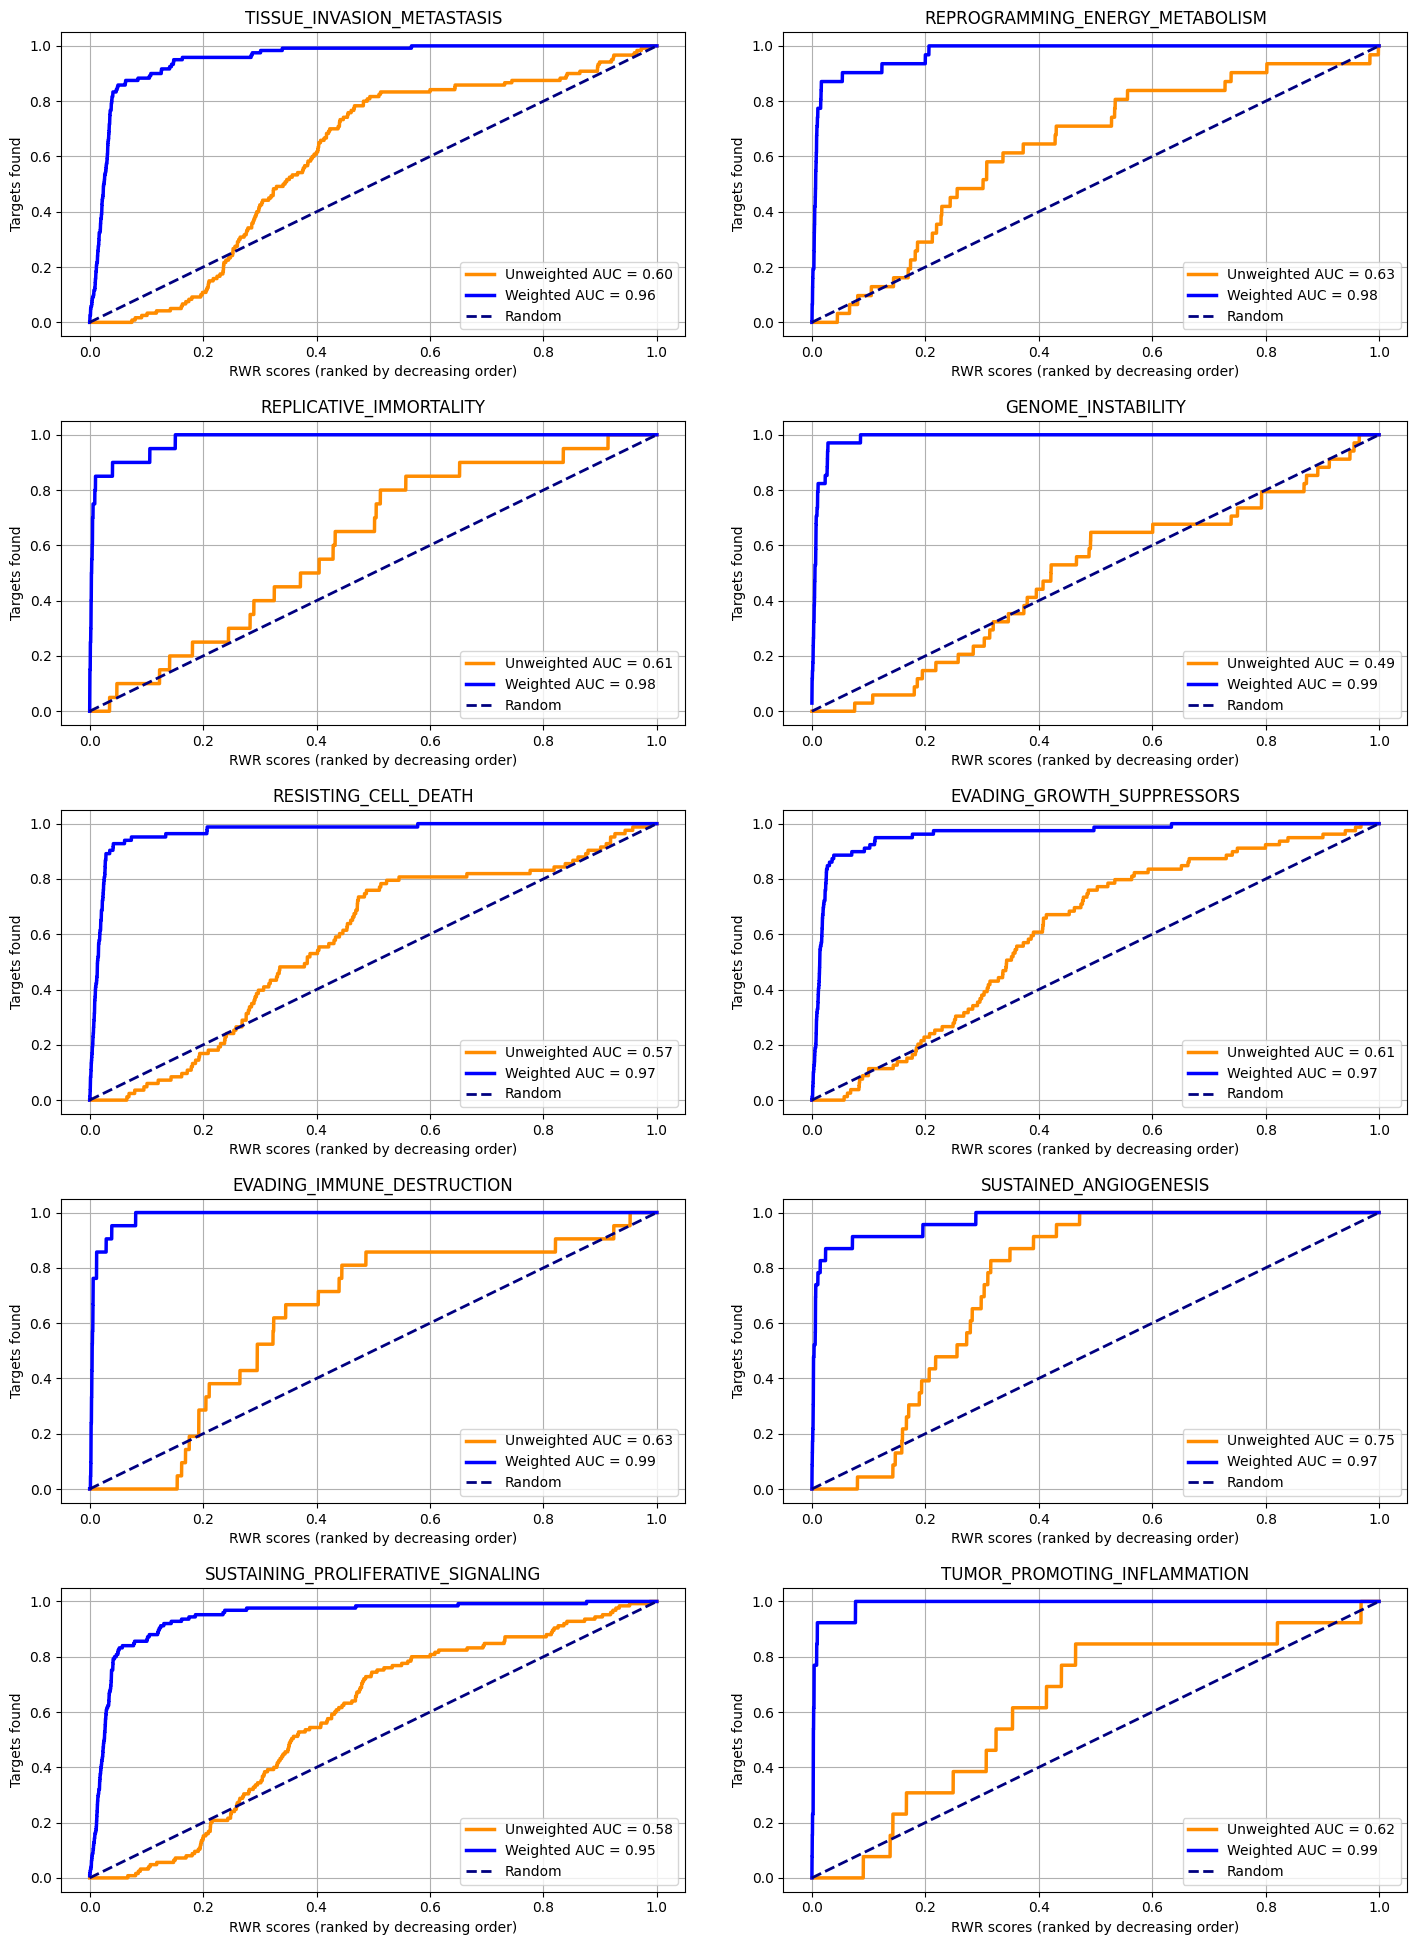

In [14]:
fig, axes = plt.subplots(nrows=5, ncols=2, figsize=(15, 20))
plt.tight_layout(pad=4.0)

for i, (hallmark_id, hallmark_name) in enumerate(dico_hallmarks_ids.items()):
    row = i // 2 
    col = i % 2

    # --- UNWEIGHTED ---
    seeds_file_unweighted = f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRUnweightedClique0_7/output_{hallmark_name}/{hallmark_name}_seeds.txt"
    targets_file_unweighted = f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRUnweightedClique0_7/output_{hallmark_name}/{hallmark_name}_targets.txt"
    scores_file_unweighted = f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRUnweightedClique0_7/output_{hallmark_name}/multiplex_1.tsv"

    df_scores_unweighted = pd.read_csv(scores_file_unweighted, sep='\t')
    with open(seeds_file_unweighted, 'r') as f:
        seeds = set(line.strip() for line in f if line.strip())
    with open(targets_file_unweighted, 'r') as f:
        targets = set(line.strip() for line in f if line.strip())
    df_scores_unweighted['is_target'] = df_scores_unweighted['node'].isin(targets).astype(int)
    df_scores_unweighted['is_seed'] = df_scores_unweighted['node'].isin(seeds).astype(int)
    df_scores_unweighted = df_scores_unweighted.sort_values('score', ascending=False).reset_index(drop=True)

    n_targets = df_scores_unweighted['is_target'].sum()
    n_total = len(df_scores_unweighted)
    n_non_targets = n_total - n_targets
    cumulative_targets = np.cumsum(df_scores_unweighted['is_target'].values)
    cumulative_non_targets = np.cumsum((1 - df_scores_unweighted['is_target']).values)
    positions = np.arange(len(df_scores_unweighted)) + 1
    positions_fraction = positions / len(df_scores_unweighted)
    tpr_unweighted = cumulative_targets / n_targets
    fpr_unweighted = cumulative_non_targets / n_non_targets
    auc_score_unweighted = auc(fpr_unweighted, tpr_unweighted)

    # --- WEIGHTED ---
    seeds_file_weighted = f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedClique0_7/output_{hallmark_name}/{hallmark_name}_seeds.txt"
    targets_file_weighted = f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedClique0_7/output_{hallmark_name}/{hallmark_name}_targets.txt"
    scores_file_weighted = f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedClique0_7/output_{hallmark_name}/multiplex_1.tsv"

    df_scores_weighted = pd.read_csv(scores_file_weighted, sep='\t')
    with open(seeds_file_weighted, 'r') as f:
        seeds = set(line.strip() for line in f if line.strip())
    with open(targets_file_weighted, 'r') as f:
        targets = set(line.strip() for line in f if line.strip())
    df_scores_weighted['is_target'] = df_scores_weighted['node'].isin(targets).astype(int)
    df_scores_weighted['is_seed'] = df_scores_weighted['node'].isin(seeds).astype(int)
    df_scores_weighted = df_scores_weighted.sort_values('score', ascending=False).reset_index(drop=True)

    n_targets = df_scores_weighted['is_target'].sum()
    n_total = len(df_scores_weighted)
    n_non_targets = n_total - n_targets
    cumulative_targets = np.cumsum(df_scores_weighted['is_target'].values)
    cumulative_non_targets = np.cumsum((1 - df_scores_weighted['is_target']).values)
    positions = np.arange(len(df_scores_weighted)) + 1
    positions_fraction = positions / len(df_scores_weighted)
    tpr_weighted = cumulative_targets / n_targets
    fpr_weighted = cumulative_non_targets / n_non_targets
    auc_score_weighted = auc(fpr_weighted, tpr_weighted)

    axes[row, col].plot(positions_fraction, tpr_unweighted, linewidth=2.5,
                        label=f'Unweighted AUC = {auc_score_unweighted:.2f}', color='darkorange')
    axes[row, col].plot(positions_fraction, tpr_weighted, linewidth=2.5,
                        label=f'Weighted AUC = {auc_score_weighted:.2f}', color='blue')
    axes[row, col].plot([0, 1], [0, 1], '--', linewidth=2, label='Random', color='navy')
    axes[row, col].set_xlabel('RWR scores (ranked by decreasing order)')
    axes[row, col].set_ylabel('Targets found')
    axes[row, col].set_title(f'{hallmark_name}')
    axes[row, col].legend(loc="lower right")
    axes[row, col].grid(True)

output_dir = "../../../../Results/PathwayComembership/09_ValidationRWR/RWR_combined_ROC/"
os.makedirs(output_dir, exist_ok=True)
plt.savefig(f"{output_dir}/Figure6.svg", format="svg", bbox_inches="tight")
plt.savefig(f"{output_dir}/Figure6.eps", format="eps", bbox_inches="tight")
plt.show()

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


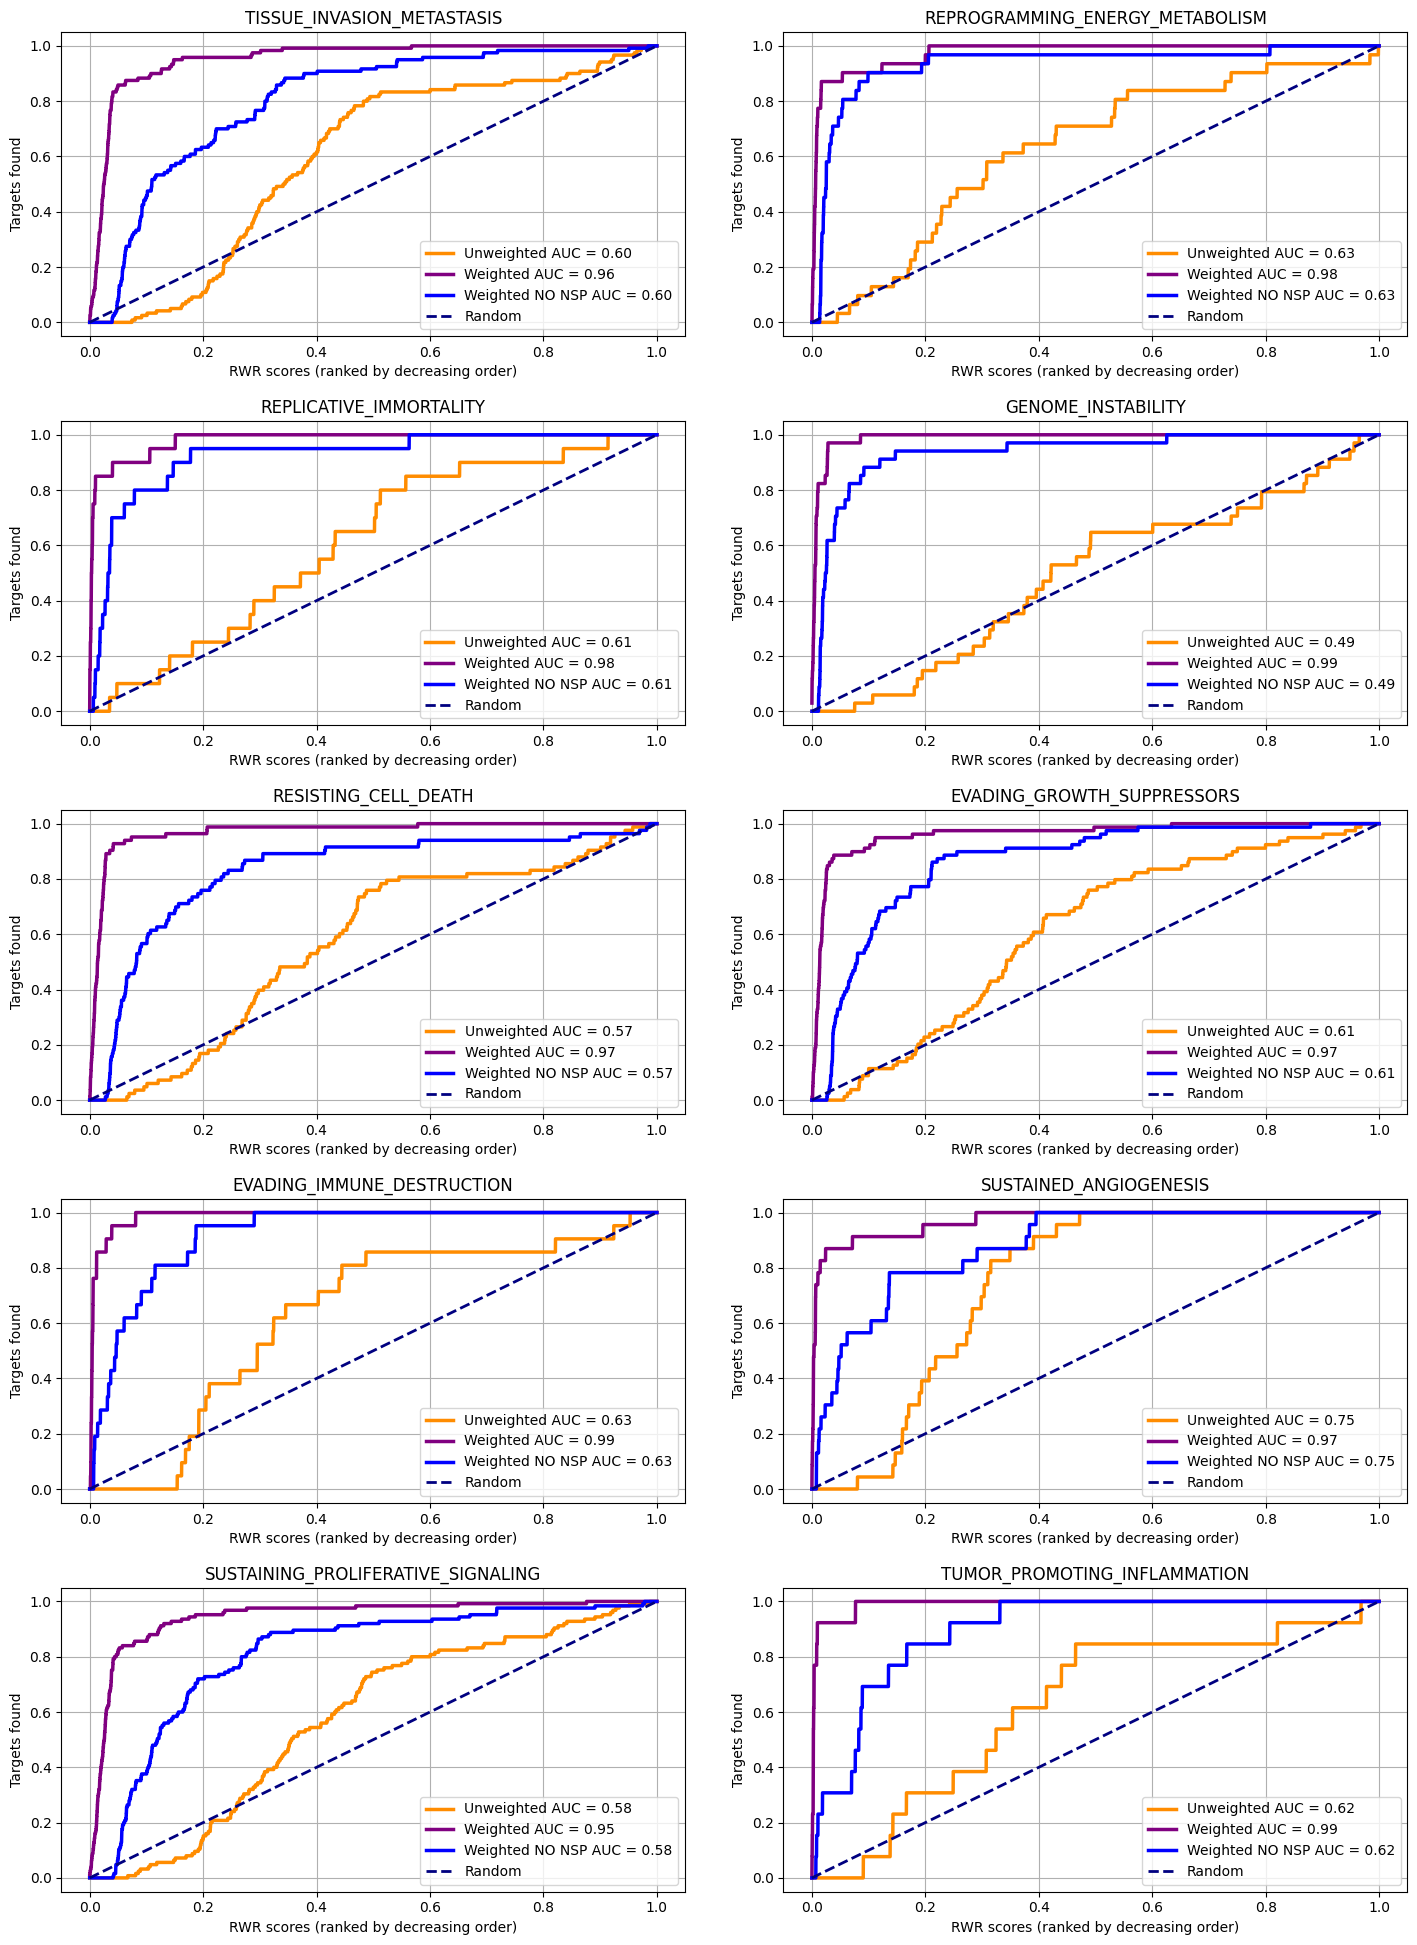

In [15]:
fig, axes = plt.subplots(nrows=5, ncols=2, figsize=(15, 20))
plt.tight_layout(pad=4.0)

for i, (hallmark_id, hallmark_name) in enumerate(dico_hallmarks_ids.items()):
    row = i // 2 
    col = i % 2

    # --- UNWEIGHTED ---
    seeds_file_unweighted = f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRUnweightedClique0_7/output_{hallmark_name}/{hallmark_name}_seeds.txt"
    targets_file_unweighted = f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRUnweightedClique0_7/output_{hallmark_name}/{hallmark_name}_targets.txt"
    scores_file_unweighted = f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRUnweightedClique0_7/output_{hallmark_name}/multiplex_1.tsv"

    df_scores_unweighted = pd.read_csv(scores_file_unweighted, sep='\t')
    with open(seeds_file_unweighted, 'r') as f:
        seeds = set(line.strip() for line in f if line.strip())
    with open(targets_file_unweighted, 'r') as f:
        targets = set(line.strip() for line in f if line.strip())
    df_scores_unweighted['is_target'] = df_scores_unweighted['node'].isin(targets).astype(int)
    df_scores_unweighted['is_seed'] = df_scores_unweighted['node'].isin(seeds).astype(int)
    df_scores_unweighted = df_scores_unweighted.sort_values('score', ascending=False).reset_index(drop=True)

    n_targets = df_scores_unweighted['is_target'].sum()
    n_total = len(df_scores_unweighted)
    n_non_targets = n_total - n_targets
    cumulative_targets = np.cumsum(df_scores_unweighted['is_target'].values)
    cumulative_non_targets = np.cumsum((1 - df_scores_unweighted['is_target']).values)
    positions = np.arange(len(df_scores_unweighted)) + 1
    positions_fraction = positions / len(df_scores_unweighted)
    tpr_unweighted = cumulative_targets / n_targets
    fpr_unweighted = cumulative_non_targets / n_non_targets
    auc_score_unweighted = auc(fpr_unweighted, tpr_unweighted)

    # WEIGHTED WITHOUT NSP
    seeds_file_unweighted = f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedCliqueNO_NSP_0_7/output_{hallmark_name}/{hallmark_name}_seeds.txt"
    targets_file_unweighted = f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedCliqueNO_NSP_0_7/output_{hallmark_name}/{hallmark_name}_targets.txt"
    scores_file_unweighted = f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedCliqueNO_NSP_0_7/output_{hallmark_name}/multiplex_1.tsv"

    df_scores_unweighted = pd.read_csv(scores_file_unweighted, sep='\t')
    with open(seeds_file_unweighted, 'r') as f:
        seeds = set(line.strip() for line in f if line.strip())
    with open(targets_file_unweighted, 'r') as f:
        targets = set(line.strip() for line in f if line.strip())
    df_scores_unweighted['is_target'] = df_scores_unweighted['node'].isin(targets).astype(int)
    df_scores_unweighted['is_seed'] = df_scores_unweighted['node'].isin(seeds).astype(int)
    df_scores_unweighted = df_scores_unweighted.sort_values('score', ascending=False).reset_index(drop=True)

    n_targets = df_scores_unweighted['is_target'].sum()
    n_total = len(df_scores_unweighted)
    n_non_targets = n_total - n_targets
    cumulative_targets = np.cumsum(df_scores_unweighted['is_target'].values)
    cumulative_non_targets = np.cumsum((1 - df_scores_unweighted['is_target']).values)
    positions = np.arange(len(df_scores_unweighted)) + 1
    positions_fraction = positions / len(df_scores_unweighted)
    tpr_weighted_no_nsp = cumulative_targets / n_targets
    fpr_weighted_no_nsp = cumulative_non_targets / n_non_targets
    auc_score_weighted_no_nsp = auc(fpr_unweighted, tpr_unweighted)

    # --- WEIGHTED ---
    seeds_file_weighted = f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedClique0_7/output_{hallmark_name}/{hallmark_name}_seeds.txt"
    targets_file_weighted = f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedClique0_7/output_{hallmark_name}/{hallmark_name}_targets.txt"
    scores_file_weighted = f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedClique0_7/output_{hallmark_name}/multiplex_1.tsv"

    df_scores_weighted = pd.read_csv(scores_file_weighted, sep='\t')
    with open(seeds_file_weighted, 'r') as f:
        seeds = set(line.strip() for line in f if line.strip())
    with open(targets_file_weighted, 'r') as f:
        targets = set(line.strip() for line in f if line.strip())
    df_scores_weighted['is_target'] = df_scores_weighted['node'].isin(targets).astype(int)
    df_scores_weighted['is_seed'] = df_scores_weighted['node'].isin(seeds).astype(int)
    df_scores_weighted = df_scores_weighted.sort_values('score', ascending=False).reset_index(drop=True)

    n_targets = df_scores_weighted['is_target'].sum()
    n_total = len(df_scores_weighted)
    n_non_targets = n_total - n_targets
    cumulative_targets = np.cumsum(df_scores_weighted['is_target'].values)
    cumulative_non_targets = np.cumsum((1 - df_scores_weighted['is_target']).values)
    positions = np.arange(len(df_scores_weighted)) + 1
    positions_fraction = positions / len(df_scores_weighted)
    tpr_weighted = cumulative_targets / n_targets
    fpr_weighted = cumulative_non_targets / n_non_targets
    auc_score_weighted = auc(fpr_weighted, tpr_weighted)

    axes[row, col].plot(positions_fraction, tpr_unweighted, linewidth=2.5,
                        label=f'Unweighted AUC = {auc_score_unweighted:.2f}', color='darkorange')
    axes[row, col].plot(positions_fraction, tpr_weighted, linewidth=2.5,
                            label=f'Weighted AUC = {auc_score_weighted:.2f}', color='purple')
    axes[row, col].plot(positions_fraction, tpr_weighted_no_nsp, linewidth=2.5,
                        label=f'Weighted NO NSP AUC = {auc_score_weighted_no_nsp:.2f}', color='blue')
    axes[row, col].plot([0, 1], [0, 1], '--', linewidth=2, label='Random', color='navy')
    axes[row, col].set_xlabel('RWR scores (ranked by decreasing order)')
    axes[row, col].set_ylabel('Targets found')
    axes[row, col].set_title(f'{hallmark_name}')
    axes[row, col].legend(loc="lower right")
    axes[row, col].grid(True)

output_dir = "../../../../Results/PathwayComembership/09_ValidationRWR/RWR_combined_ROC/"
os.makedirs(output_dir, exist_ok=True)
plt.savefig(f"{output_dir}/Figure6.svg", format="svg", bbox_inches="tight")
plt.savefig(f"{output_dir}/Figure6.eps", format="eps", bbox_inches="tight")
plt.show()

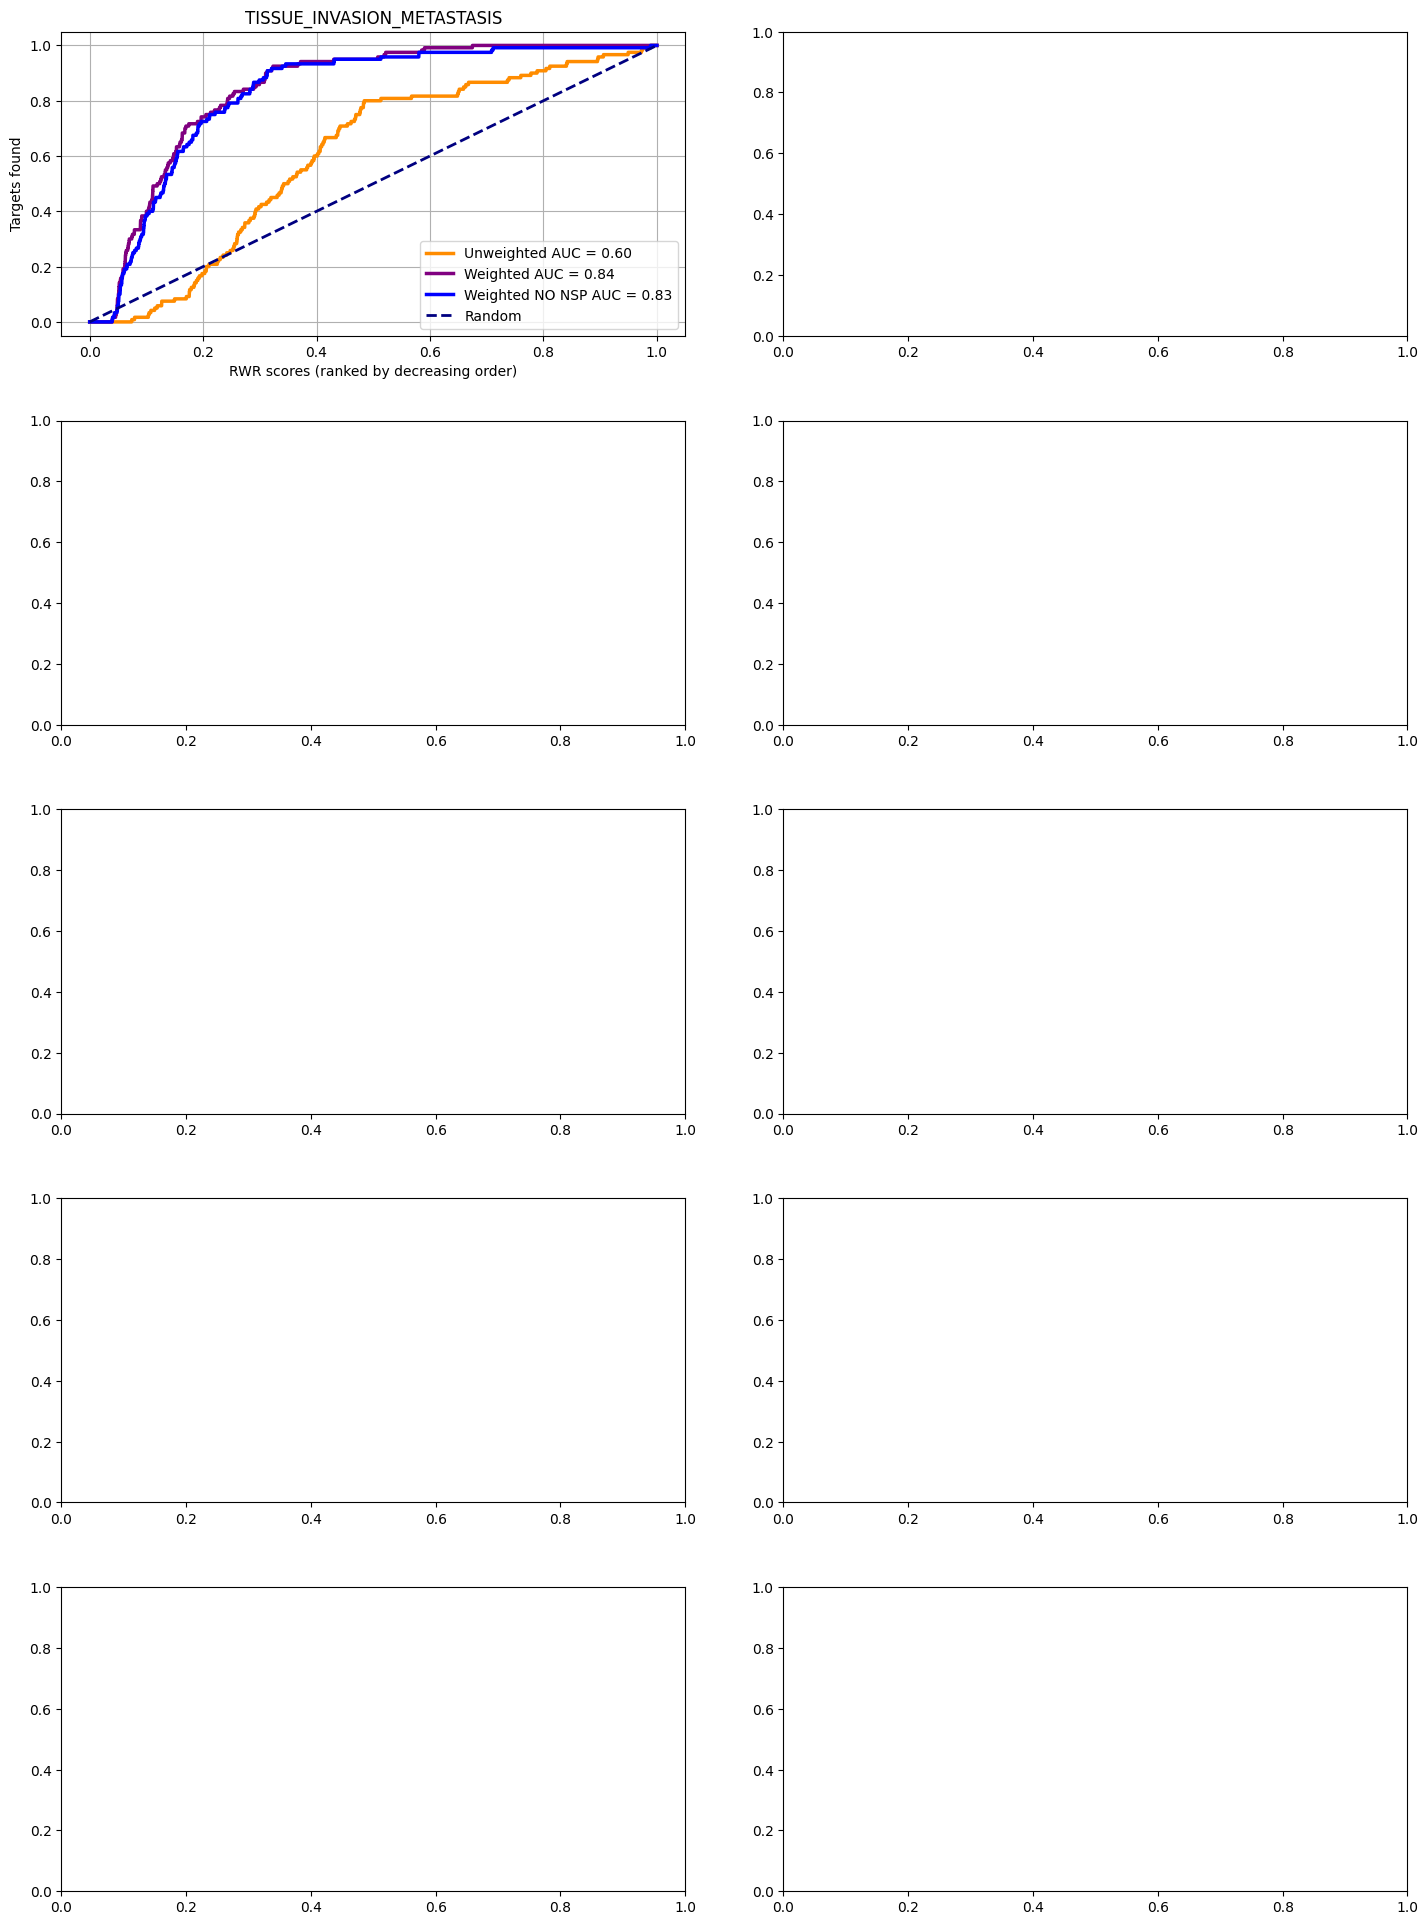

In [18]:
fig, axes = plt.subplots(nrows=5, ncols=2, figsize=(15, 20))
plt.tight_layout(pad=4.0)

for i, (hallmark_id, hallmark_name) in enumerate(dico_hallmarks_ids.items()):
    row = i // 2 
    col = i % 2

    # --- UNWEIGHTED ---
    seeds_file_unweighted = f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRUnweightedClique0_7/output_{hallmark_name}/{hallmark_name}_seeds.txt"
    targets_file_unweighted = f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRUnweightedClique0_7/output_{hallmark_name}/{hallmark_name}_targets.txt"
    scores_file_unweighted = f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRUnweightedClique0_7/output_{hallmark_name}/multiplex_1.tsv"

    df_scores_unweighted = pd.read_csv(scores_file_unweighted, sep='\t')
    with open(seeds_file_unweighted, 'r') as f:
        seeds_unweighted = set(line.strip() for line in f if line.strip())
    with open(targets_file_unweighted, 'r') as f:
        targets_unweighted = set(line.strip() for line in f if line.strip())
    df_scores_unweighted['is_target'] = df_scores_unweighted['node'].isin(targets_unweighted).astype(int)
    df_scores_unweighted['is_seed'] = df_scores_unweighted['node'].isin(seeds_unweighted).astype(int)
    df_scores_unweighted = df_scores_unweighted.sort_values('score', ascending=False).reset_index(drop=True)

    n_targets_unweighted = df_scores_unweighted['is_target'].sum()
    n_total_unweighted = len(df_scores_unweighted)
    n_non_targets_unweighted = n_total_unweighted - n_targets_unweighted
    cumulative_targets_unweighted = np.cumsum(df_scores_unweighted['is_target'].values)
    cumulative_non_targets_unweighted = np.cumsum((1 - df_scores_unweighted['is_target']).values)
    positions_unweighted = np.arange(len(df_scores_unweighted)) + 1
    positions_fraction_unweighted = positions_unweighted / len(df_scores_unweighted)
    tpr_unweighted = cumulative_targets_unweighted / n_targets_unweighted
    fpr_unweighted = cumulative_non_targets_unweighted / n_non_targets_unweighted
    auc_score_unweighted = auc(fpr_unweighted, tpr_unweighted)

    # WEIGHTED WITHOUT NSP
    seeds_file_no_nsp = f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedCliqueNO_NSP_0_7/output_{hallmark_name}/{hallmark_name}_seeds.txt"
    targets_file_no_nsp = f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedCliqueNO_NSP_0_7/output_{hallmark_name}/{hallmark_name}_targets.txt"
    scores_file_nsp = f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedCliqueNO_NSP_0_7/output_{hallmark_name}/multiplex_1.tsv"

    df_scores_no_nsp = pd.read_csv(scores_file_nsp, sep='\t')
    with open(seeds_file_no_nsp, 'r') as f:
        seeds_no_nsp = set(line.strip() for line in f if line.strip())
    with open(targets_file_no_nsp, 'r') as f:
        targets_no_nsp = set(line.strip() for line in f if line.strip())
    df_scores_no_nsp['is_target'] = df_scores_no_nsp['node'].isin(targets_no_nsp).astype(int)
    df_scores_no_nsp['is_seed'] = df_scores_no_nsp['node'].isin(seeds_no_nsp).astype(int)
    df_scores_no_nsp = df_scores_no_nsp.sort_values('score', ascending=False).reset_index(drop=True)

    n_targets_no_nsp = df_scores_no_nsp['is_target'].sum()
    n_total_no_nsp = len(df_scores_no_nsp)
    n_non_targets_no_nsp = n_total_no_nsp - n_targets_no_nsp
    cumulative_targets_no_nsp = np.cumsum(df_scores_no_nsp['is_target'].values)
    cumulative_non_targets_no_nsp = np.cumsum((1 - df_scores_no_nsp['is_target']).values)
    positions_no_nsp = np.arange(len(df_scores_no_nsp)) + 1
    positions_fraction_no_nsp = positions_no_nsp / len(df_scores_no_nsp)
    tpr_weighted_no_nsp = cumulative_targets_no_nsp / n_targets_no_nsp
    fpr_weighted_no_nsp = cumulative_non_targets_no_nsp / n_non_targets_no_nsp
    auc_score_weighted_no_nsp = auc(fpr_weighted_no_nsp, tpr_weighted_no_nsp)

    # --- WEIGHTED ---
    seeds_file_weighted = f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedClique0_7/output_{hallmark_name}/{hallmark_name}_seeds.txt"
    targets_file_weighted = f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedClique0_7/output_{hallmark_name}/{hallmark_name}_targets.txt"
    scores_file_weighted = f"../../../../Results/PathwayComembership/09_ValidationRWR/RWRWeightedClique0_7/output_{hallmark_name}/multiplex_1.tsv"

    df_scores_weighted = pd.read_csv(scores_file_weighted, sep='\t')
    with open(seeds_file_weighted, 'r') as f:
        seeds_weighted = set(line.strip() for line in f if line.strip())
    with open(targets_file_weighted, 'r') as f:
        targets_weighted = set(line.strip() for line in f if line.strip())
    df_scores_weighted['is_target'] = df_scores_weighted['node'].isin(targets_weighted).astype(int)
    df_scores_weighted['is_seed'] = df_scores_weighted['node'].isin(seeds_weighted).astype(int)
    df_scores_weighted = df_scores_weighted.sort_values('score', ascending=False).reset_index(drop=True)

    n_targets_weighted = df_scores_weighted['is_target'].sum()
    n_total_weighted = len(df_scores_weighted)
    n_non_targets_weighted = n_total_weighted - n_targets_weighted
    cumulative_targets_weighted = np.cumsum(df_scores_weighted['is_target'].values)
    cumulative_non_targets_weighted = np.cumsum((1 - df_scores_weighted['is_target']).values)
    positions_weighted = np.arange(len(df_scores_weighted)) + 1
    positions_fraction_weighted = positions_weighted / len(df_scores_weighted)
    tpr_weighted = cumulative_targets_weighted / n_targets_weighted
    fpr_weighted = cumulative_non_targets_weighted / n_non_targets_weighted
    auc_score_weighted = auc(fpr_weighted, tpr_weighted)

    axes[row, col].plot(positions_fraction_unweighted, tpr_unweighted, linewidth=2.5,
                        label=f'Unweighted AUC = {auc_score_unweighted:.2f}', color='darkorange')
    axes[row, col].plot(positions_fraction_weighted, tpr_weighted, linewidth=2.5,
                            label=f'Weighted AUC = {auc_score_weighted:.2f}', color='purple')
    axes[row, col].plot(positions_fraction_no_nsp, tpr_weighted_no_nsp, linewidth=2.5,
                        label=f'Weighted NO NSP AUC = {auc_score_weighted_no_nsp:.2f}', color='blue')
    axes[row, col].plot([0, 1], [0, 1], '--', linewidth=2, label='Random', color='navy')
    axes[row, col].set_xlabel('RWR scores (ranked by decreasing order)')
    axes[row, col].set_ylabel('Targets found')
    axes[row, col].set_title(f'{hallmark_name}')
    axes[row, col].legend(loc="lower right")
    axes[row, col].grid(True)

output_dir = "../../../../Results/PathwayComembership/09_ValidationRWR/RWR_combined_ROC/"
os.makedirs(output_dir, exist_ok=True)
# plt.savefig(f"{output_dir}/Figure6.svg", format="svg", bbox_inches="tight")
# plt.savefig(f"{output_dir}/Figure6.eps", format="eps", bbox_inches="tight")
plt.show()